# A system of ODEs: Method 3 - using SciPy's ```odeint```

In [1]:
# our standard import
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format='retina' # hig-res plots for a Retina display
# import odeint
from scipy.integrate import odeint

## A predator-prey relationship for Rabbits and Foxes

The predator-prey relationship is a classic coupled ODE system. Here we describe the coupled population dynamics of rabbits, $R$, and foxes, $F$, with the following:

\begin{align}
\frac{dR}{dt} &= aR-bRF \\
\frac{dF}{dt} &= -lF+kRF 
\end{align}

where $R$ and $F$ are the population values of rabbits and foxes. The coefficients are defined as:

\begin{align}
a &= \text{base birth rate of rabits}  \\
b &= \text{prey factor}  \\
l &= \text{fox base diminishing rate}\\
k &= \text{feeding rate}
\end{align}

This coupled system of equations is solved below using SciPy's ```odeint``` (for more information see the [SciPy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.odeint.html)).

## Method 3: using Scipy ```odeint```

In [2]:
# --- User input ------------

# define the ODE system of equations
def df(ic,t): # the variable order matters need ic and then the array long which to integrate.
    R, F = ic[0], ic[1]
    dR = a*R-b*R*F
    dF = -l*F+k*R*F
    return [dR, dF]

# define the number of points and the start and stop locations
start = 0
end = 50
dt = 0.01
R_0 = 500
F_0 = 100

# define the coefficients
a = 0.5   # base birth rate of rabits
b = 0.01 # pray factor
l = 1      # fox base diminishing rate
k = 0.005  # feeding rate

# --- Calculations ------------

# setup the t array
t = np.arange(start,end,dt)

# set the initial conditions
ic = [R_0,F_0]

# solve using odeint 
y = odeint(df,ic,t)

In [6]:
# look at the solution
y

array([[500.        , 100.        ],
       [497.46884711, 101.50490875],
       [494.87579019, 103.01926819],
       ...,
       [218.16183945,   4.65853816],
       [219.15321582,   4.66288594],
       [220.14899892,   4.66746966]])

In [4]:
y.shape

(5000, 2)

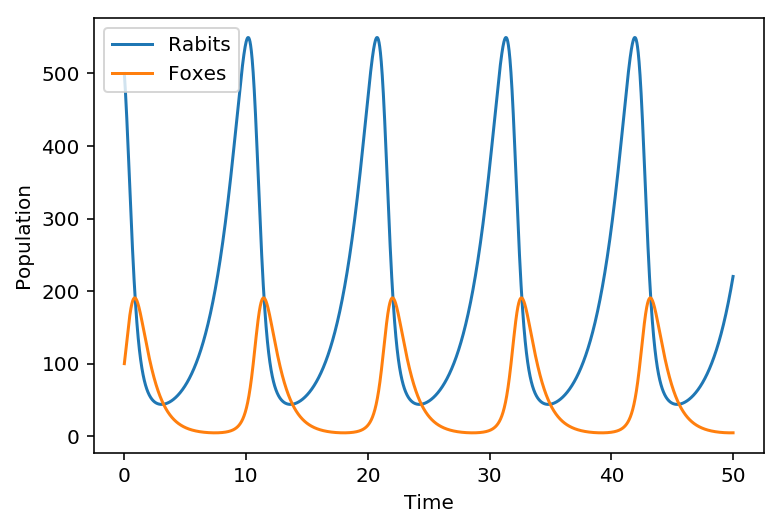

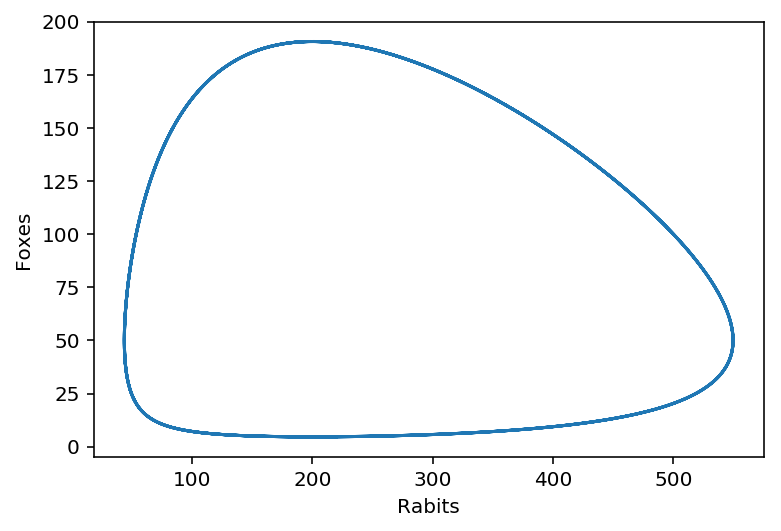

In [7]:
# --- plot the results  ------------

fig, ax = plt.subplots()
ax.plot(t,y[:,0], label='Rabits')
ax.plot(t,y[:,1], label='Foxes')
ax.set_xlabel('Time')
ax.set_ylabel('Population')
plt.legend()

fig, ax = plt.subplots()
ax.plot(y[:,0],y[:,1])
ax.set_xlabel('Rabits')
ax.set_ylabel('Foxes');

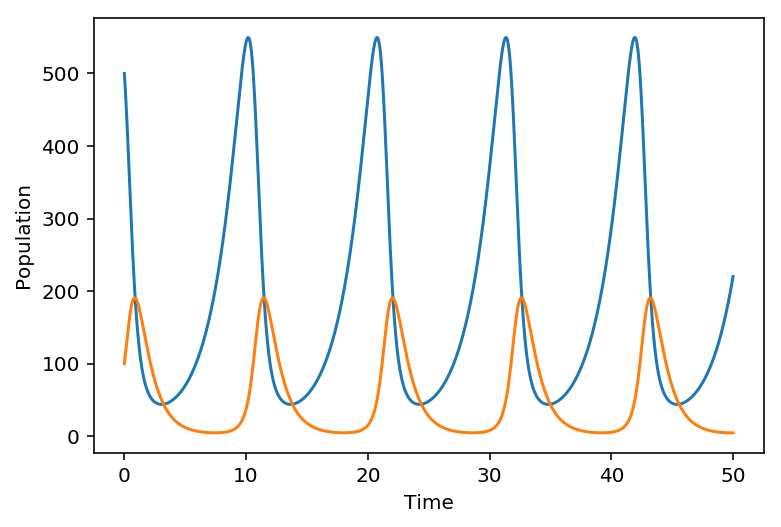

In [8]:
# --- plot the results (all in one go) ------------

fig, ax = plt.subplots()
ax.plot(t,y)
ax.set_xlabel('Time')
ax.set_ylabel('Population');